<a href="https://colab.research.google.com/github/Mamayonaise/CS430_Assignment2/blob/main/CS430_Assignment2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part 1 – Get to Know the Prediction Problem (15 points)

1. Load the dataset and examine its structure.
*   Load the CSV file into pandas.
*   Display the first 5 rows.
*   Report the number of rows and columns.
*   Print the column names.
*   Use info() to inspect the dataset.






In [1]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Assignment2/SLCM_rent_arrears_student_clean.csv")

df.head()

,record_id,adults_in_household,children_in_household,household_has_65plus,monthly_household_income,income_sources,employment_status,has_housing_voucher,eviction_in_progress,behind_on_utilities,main_reason_behind_on_rent,intake_quarter,monthly_rent,past_due_rent
0,SLCM_0001,1,1,No,293.0,"Food benefits - TANF/SNAP, No income, Other",Unemployed but want to find work,No,I don't know,Yes,Other,2026-Q1,1560.0,3100.0
1,SLCM_0002,0,3,No,2000.0,Child support,Employed,No,I don't know,Yes,Unexpected expense,2026-Q3,1550.0,7300.0
2,SLCM_0003,1,0,No,400.0,Food benefits - TANF/SNAP,Unemployed but want to find work,I don't know,Yes,Yes,Lost a job/had hours cut,2025-Q4,0.0,6000.0
3,SLCM_0004,2,0,No,2500.0,Full-time employment,Unemployed and not looking for work,No,Yes,Yes,Lost a job/had hours cut,2026-Q2,1299.0,2500.0
4,SLCM_0005,1,2,No,14.0,Part-time employment,Employed,No,Yes,No,Unexpected expense,2025-Q4,1105.5,1205.5


In [2]:
df.shape

(1754, 14)

**My Respone**


---


There are:


*   **1754** rows
*   **14** columns



In [3]:
df.columns

Index(['record_id', 'adults_in_household', 'children_in_household',
       'household_has_65plus', 'monthly_household_income', 'income_sources',
       'employment_status', 'has_housing_voucher', 'eviction_in_progress',
       'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter',
       'monthly_rent', 'past_due_rent'],
      dtype='object')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1754 entries, 0 to 1753
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   record_id                   1754 non-null   object 
 1   adults_in_household         1754 non-null   int64  
 2   children_in_household       1754 non-null   int64  
 3   household_has_65plus        1754 non-null   object 
 4   monthly_household_income    1646 non-null   float64
 5   income_sources              1754 non-null   object 
 6   employment_status           1754 non-null   object 
 7   has_housing_voucher         1754 non-null   object 
 8   eviction_in_progress        1753 non-null   object 
 9   behind_on_utilities         1747 non-null   object 
 10  main_reason_behind_on_rent  1738 non-null   object 
 11  intake_quarter              1754 non-null   object 
 12  monthly_rent                1746 non-null   float64
 13  past_due_rent               1754 


Which variable will be the target?
*   past_due_rent


Which columns appear to be numerical?

*   adults_in_household
*   children_in_household
*   monthly_household_income
*   monthly_rent
*   past_due_rent

Which columns appear to be categorical?


*   record_id
*   household_has_65plus
*   income_sources
*   employee_status
*   has_housing_voucher
*   eviction_in_progress
*   behind_on_utilities
*   main_reason_behind_on_rent
*   intake_quarter



2. Investigate missing values.

* Calculate the number of missing values in every column.
* Identify which variables contain missing data.
* Briefly describe how you plan to handle those missing values before modeling.

Do not simply remove all rows with missing data unless you can justify that decision

In [5]:
df.isnull().sum()

,0
record_id,0
adults_in_household,0
children_in_household,0
household_has_65plus,0
monthly_household_income,108
income_sources,0
employment_status,0
has_housing_voucher,0
eviction_in_progress,1
behind_on_utilities,7


**My Response**


---


Variables Countaining Missing Data

* monthly_household_income
* eviction_in_progress
* behind_on_utilities
* main_reason_behind_on_rent
* monthly_rent

Plan For Missing Variables:


---



For the Numeric Vars, I'll use median imputation to estimate an average as using the median is good to get around outliers. I'll fill in missing values with the median of the present values.

For the Categorical Vars, I'll fill in missing values with "Unknown"

### 3. Explore the target variable: `past_due_rent`.

**Calculate:**
- count
- mean
- median
- standard deviation
- minimum
- maximum

**Create:**
- a histogram
- a boxplot

**Answer:**
- What does the distribution look like?
- Is the distribution symmetric or skewed?
- Are the mean and median similar?
- Do you notice any unusually high values?
- Why might rent-arrears data naturally contain a wide range of values?

*Do not automatically remove an observation simply because it is high.*

In [6]:
df['past_due_rent'].describe()

,past_due_rent
count,1754.000000
mean,2408.006933
std,2089.515372
min,0.000000
25%,1050.000000
50%,2000.000000
75%,3200.000000
max,20000.000000


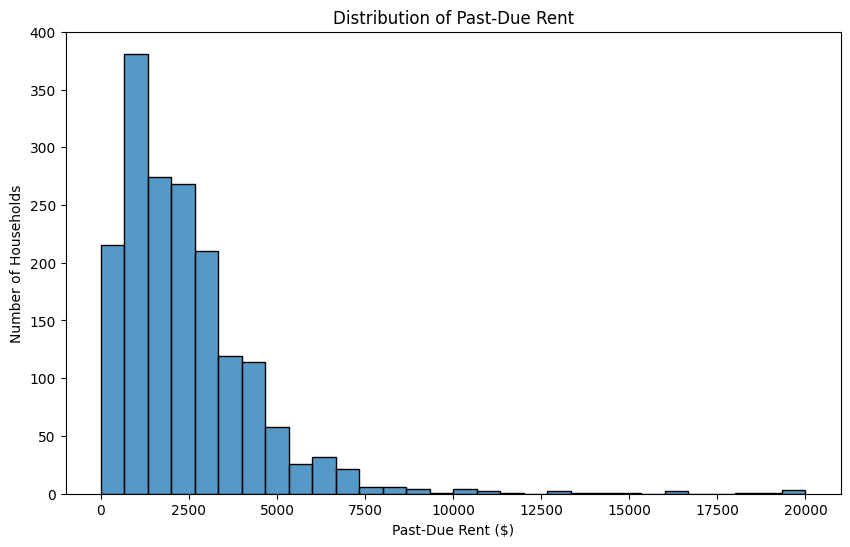

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(df['past_due_rent'], bins=30)
plt.title('Distribution of Past-Due Rent')
plt.xlabel('Past-Due Rent ($)')
plt.ylabel('Number of Households')
plt.show()

Text(0.5, 0, 'Past-Due Rent ($)')

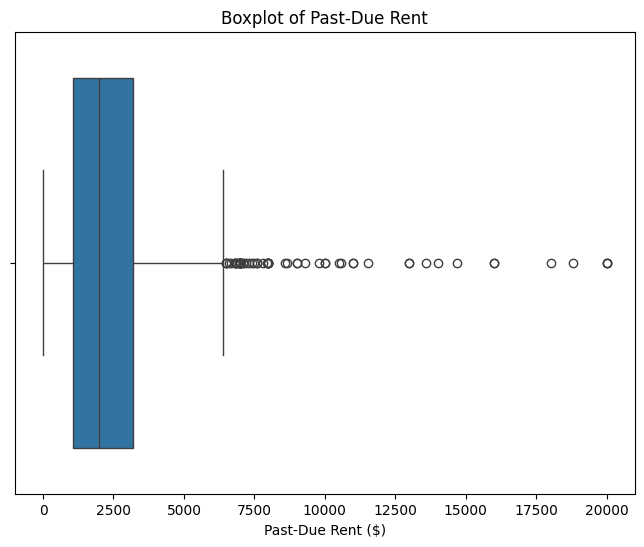

In [8]:
# create a boxplot for the target variable past_due_rent
plt.figure(figsize=(8, 6))
sns.boxplot(x=df['past_due_rent'])
plt.title('Boxplot of Past-Due Rent')
plt.xlabel('Past-Due Rent ($)')

**My Response**


---

1. The data is skewed to the right
2. The mean and median are kind of close but not close enough to be counted as the same
3. There are quite a lot of outliers, all the way to near 20k which is roughly 10 times the median OR roughly 8 times the mean
4. First off, some of the data may just be wrong, but besides that, people live in many different types of homes. Some may live in a small place that isn't populated much, lowering rent. Others live in bustling urban environments which are known to have high rent. Also, generally in any part of the world, most people are not wealthy on a grand scale, which is why so much of the later outliers are so few in number.

### 4. Create your input features and target.

Create `X` and `y` using `past_due_rent` as the target. Do not use `record_id` as an input feature.

**Answer:**
- Why should `record_id` not be used to predict past-due rent?

In [9]:
X = df.drop(columns=['record_id', 'past_due_rent'])
y = df['past_due_rent']

print("X Shape:", X.shape)
print("Y Shape:", y.shape)

X Shape: (1754, 12)
Y Shape: (1754,)


In [10]:
df['record_id'].value_counts()

,count
record_id,
SLCM_1754,1
SLCM_0001,1
SLCM_0002,1
SLCM_0003,1
SLCM_0004,1
...,...
SLCM_0015,1
SLCM_0014,1
SLCM_0013,1


**My Response**


---


The variable `'record_id` is simply a label for each row of the dataset so it is not needed for predictions

### 5. Separate the numerical and categorical features.

- Create lists containing numerical features and categorical features.
- Display both lists.
- Briefly explain why machine-learning models require different preparation steps for numerical and categorical variables.

In [11]:
numerical_features = ['adults_in_household', 'children_in_household', 'monthly_household_income', 'monthly_rent']
categorical_features = ['household_has_65plus', 'income_sources', 'employment_status',
                        'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities',
                        'main_reason_behind_on_rent', 'intake_quarter']

numerical_features, categorical_features

(['adults_in_household',
  'children_in_household',
  'monthly_household_income',
  'monthly_rent'],
 ['household_has_65plus',
  'income_sources',
  'employment_status',
  'has_housing_voucher',
  'eviction_in_progress',
  'behind_on_utilities',
  'main_reason_behind_on_rent',
  'intake_quarter'])

Categorical Data is very interpretive and messy to manage. Implementing categorical data in a model is impossible as models do math and categories are not numbers. You can on occasion turn categories to numbers, but that is even always needed.

Numerical Data on the other hand is more rigid and simpler. Submitted vars are mostly all unique numbers, and the missing vars will be filled in with the median. The model can take these in simply as they are and will compute the model.

### 6. Split the data into training and testing sets.

Use `test_size=0.20` and `random_state=42`.

- Report the dimensions of `X_train`, `X_test`, `y_train`, and `y_test`.
- Why should the model be evaluated using data that was not used during training?

In [12]:
# split the data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)
print("y_train Shape:", y_train.shape)
print("y_test Shape:", y_test.shape)

X_train Shape: (1403, 12)
X_test Shape: (351, 12)
y_train Shape: (1403,)
y_test Shape: (351,)


**My Response**


---


The model should be evaluated using test that was not previously used to see if the model works in any case. To do this, we simulate new households and see if the model still holds.

### 7. Prepare the numerical variables.

Create an appropriate numerical preprocessing pipeline. Your pipeline should consider missing values and feature scaling. Use appropriate tools such as `SimpleImputer` and `StandardScaler`.

**Explain:**
- How did you handle missing numerical values?
- Why might feature scaling matter when comparing Linear, Ridge, and Lasso models?

In [13]:
# create the pipeline
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

**My Response**


---


1. I fill in the missing numeric vars for `'monthly_household_income'` and `'monthly_rent'` with the median of the training data.

2. Scaling matters because Ridge and Lasso penalize the size of the numerical columns, making columns with large values get small coefficients and vice versa. If we scale, we prevent these from happening as this puts every numerical column on a similar scale so the penalty applies fairly.

### 8. Prepare the categorical variables.

Create an appropriate categorical preprocessing pipeline. Your pipeline should consider missing values and converting text categories into numerical values. Use appropriate tools such as `SimpleImputer` and `OneHotEncoder`.

**Answer:**
- Why can the regression models not directly use values such as employment categories?
- Why is one-hot encoding appropriate for these variables?
- Why would assigning arbitrary numbers such as 1, 2, 3, and 4 to unordered categories potentially be misleading?

In [14]:
#create the categorical pipeline
from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

**My Response**


---

1. You can't directly use values like employment categories because linear regression is a formula, which needs numbers to work. Multiplying a value like "Unemployed" doesn't do anything, so we need to convert the categories to numbers if we want to use the regression.
2. Using one-hot encoding is appropriate because it turns each of these categorical columns to have the values 0 or 1 (and missing values become their own "Unknown" column), so for example, for the "Employed" column would show 0 for being false and 1 otherwise. Also, none of the employment categories should be in an order, and this makes each of them mutually exclusive as they should be.
3. Assigning numbers like 1,2,3 and 4 would order the columns and that is not what we want to do here. For example: 1 -> "Employed", 2 -> "Unemployed", 3 -> "Retired": the model would treat "Retired" like it's more than the other two categories and find meaning in where there isn't any.

### 9. Combine your preprocessing steps.

Use a `ColumnTransformer` to combine the numerical and categorical preprocessing. Your preprocessing should be reusable inside the regression pipelines you create in the next part.

Explain briefly why using a preprocessing pipeline is useful.

In [15]:
# use columntransformer to combine numerical and categorical. make the preproccessing reusable

from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_features),
    ('cat', categorical_pipeline, categorical_features)
])

preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['adults_in_household',
                                  'children_in_household',
                                  'monthly_household_income', 'monthly_rent']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(fill_value='Unknown',
                                                                strategy='constant')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['household_has_65plus', 'income_sources',
                                  'employment_status', 'has_housing_voucher',
                                  'eviction_in_progress', 'behind_on_utilities',
                                  'main_reason_behind_on_rent',
                                  'intake_quarter'])])

**My Response**


---


It's useful because it gets all the preperation steps and puts them into a single reusable object that runs the same steps every time. Stuff like preventing the data from leaking, keeping the steps the data is prepared in order, etc.

### 10. Build a Multiple Linear Regression model.

Create a pipeline containing your preprocessing and a Linear Regression model. Train the model using the training data and make predictions for the testing data.

**Calculate:**
- RMSE
- R²

Create an Actual vs. Predicted scatterplot with actual values on the x-axis, predicted values on the y-axis, and a diagonal reference line showing where perfect predictions would fall.

**Answer:**
- What does RMSE represent in this problem?
- What does the R² score tell you?
- Based on the graph, how closely do the predictions match the actual values?
- Do you notice cases where the model makes large prediction errors?

In [16]:
# create pipeline containing preprocessing and linear regreassion model

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
import numpy as np

model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

#train the model using training data and make predictions
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

#calculate rmse and r^2
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Linear Regression RMSE:", round(rmse, 2))
print("Linear Regression R²:", round(r2, 4))



Linear Regression RMSE: 1851.43
Linear Regression R²: 0.1638


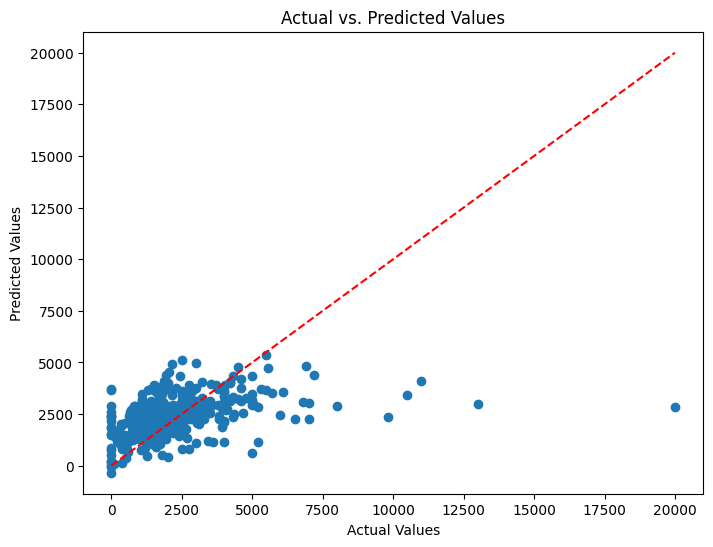

In [17]:
#create an actual vs predicted scatter plot of the data: actual values on x-axis, predicted on y, and a diagonal ref line where perfect predictions fall

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linestyle='--')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs. Predicted Values')
plt.show()


**My Response**


---


1. RMSE is the typical size of the model's prediction error, in dollars.
2. R^2 tells us how much the predicted model explains with the data used from the test data. Since R^2 ~ 0.16, the model only explains about 16% of the variation.
3. Not enough. If they were good, they would be nearby the red line, but instead they're bunched up sort of like their in a sqrt funtion or a logarithmic function in quadrant 1.
4. Yes. Some predictions are negative, and many are far up in past-due-rent (up to about 20k)


### 11. Build a Polynomial Regression model.

Real-world relationships are not always perfectly linear. For this model, use `PolynomialFeatures(degree=2, include_bias=False)`. Apply polynomial transformation to the appropriate numerical variables. Do not automatically apply polynomial expansion to all one-hot encoded categorical variables.

Train the model and calculate RMSE and R².

**Answer:**
- Did Polynomial Regression perform better or worse than Linear Regression?
- What does a degree-2 polynomial allow the model to represent that Linear Regression cannot?
- Why could using a very high polynomial degree lead to overfitting?
- Did making the model more complicated automatically make it better?

In [18]:
from sklearn.preprocessing import PolynomialFeatures

poly_numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('scaler', StandardScaler())
])

poly_preprocessor = ColumnTransformer([
    ('num', poly_numerical_pipeline, numerical_features),
    ('cat', categorical_pipeline, categorical_features)
])

poly_model = Pipeline([
    ('preprocessor', poly_preprocessor),
    ('regressor', LinearRegression())
])

poly_model.fit(X_train, y_train)
y_pred_poly = poly_model.predict(X_test)
rmse_poly = np.sqrt(mean_squared_error(y_test, y_pred_poly))
r2_poly = r2_score(y_test, y_pred_poly)

print("Polynomial Regression RMSE:", round(rmse_poly, 2))
print("Polynomial Regression R²:", round(r2_poly, 4))


Polynomial Regression RMSE: 1863.47
Polynomial Regression R²: 0.1529


**My Response**


---

1. This model preformed slightly worse than the Linear Regression model.

* Linear Regression     | RMSE: **1851.43**, R²: *0.1638*
* Polynomial Regression | RMSE: **1863.47**, R²: *0.1529*


2. It bases the model off of combinations between the features so it follows a curve rather than a straight line. The effect of monthly rent may change at higher rent levels and this could account for it.
3. It would try to find patterns in where there aren't any, essentially giving us irrelevent info. It looks good for training data, but in any other case it wouldn't work because it looks for random noise that's similar to the training data.
4. No, the extra complexity did not make it better.

### 12. Build a Ridge Regression model.

Create a Ridge Regression pipeline using the same training and testing data. Choose a reasonable value for `alpha`. You may experiment with more than one value.

Calculate RMSE and R².

**Answer:**
- How does Ridge Regression compare with Linear Regression?
- What does regularization do?
- Why can regularization be useful when a model contains many features?

In [19]:
# make a ridge regression model

from sklearn.linear_model import Ridge

ridge_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', Ridge(alpha=1.0))
])

ridge_model.fit(X_train, y_train)
y_pred_ridge = ridge_model.predict(X_test)
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
r2_ridge = r2_score(y_test, y_pred_ridge)

print("Ridge Regression RMSE:", round(rmse_ridge, 2))
print("Ridge Regression R²:", round(r2_ridge, 4))

Ridge Regression RMSE: 1837.51
Ridge Regression R²: 0.1763


**My Response**


---

1. This model performed slightly better than the Linear Regression model.

* Linear Regression     | RMSE: **1851.43**, R²: *0.1638*
* Ridge Regression      | RMSE: **1837.51**, R²: *0.1763*

2. Regularization adds another constraint other than minimizing the errors to the model: having a penalty when there are large coefficients. This keeps coefficients small so the model doesn't rely much on noise.
3. When there are many features, it allows some room to overfit. It's useful because it keeps the coefficients from getting too large which reduces overfitting and helps the model peform better with new data.

### 13. Build a Lasso Regression model.

Create a Lasso Regression pipeline using the same training and testing data. Choose a reasonable value for `alpha`.

Calculate RMSE and R².

**Answer:**
- How does Lasso compare with Linear and Ridge Regression?
- What is an important difference between Ridge and Lasso?
- What can happen to some coefficients when Lasso is used?

In [20]:
from sklearn.linear_model import Lasso

lasso_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', Lasso(alpha=1.0))
])

lasso_model.fit(X_train, y_train)
y_pred_lasso = lasso_model.predict(X_test)
rmse_lasso = np.sqrt(mean_squared_error(y_test, y_pred_lasso))
r2_lasso = r2_score(y_test, y_pred_lasso)

print("Lasso Regression RMSE:", round(rmse_lasso, 2))


print("Lasso Regression R²:", round(r2_lasso, 4))

Lasso Regression RMSE: 1828.95
Lasso Regression R²: 0.184


**My Response**


---

1. Lasso performed the best of the three.

* Linear Regression     | RMSE: **1851.43**, R²: *0.1638*
* Ridge Regression      | RMSE: **1837.51**, R²: *0.1763*
* Lasso Regression      | RMSE: **1828.95**, R²: *0.184*

2. Though both penalize the large coefficients, Ridge shrinks the coefficients in the way to zero but keeps the features, whereas Lasso can shrink some of them all the way to zero and drops the features. Essentially, Ridge keeps feature that helps if at all, and lasso does that but drops the features that barely help, only focusing on the most important features
3. Since some coefficients can be set to exactly 0, lasso just drops them completely.

### 14. Compare all four models.

Create a DataFrame containing the test-set results for all four models.

| Model | RMSE | R² |
|---|---|---|
| Linear Regression | | |
| Polynomial Regression | | |
| Ridge Regression | | |
| Lasso Regression | | |

**Answer:**
- Which model has the lowest RMSE?
- Which model has the highest R²?
- Are the differences between the models large or small?
- Did the most complicated model perform the best?
- Which model would you continue investigating? Explain your choice using evidence from your results.

In [21]:
#compare the 4 models

results = pd.DataFrame({
    'Model': ['Linear Regression', 'Polynomial Regression', 'Ridge Regression', 'Lasso Regression'],
    'RMSE': [rmse, rmse_poly, rmse_ridge, rmse_lasso],
    'R²': [r2, r2_poly, r2_ridge, r2_lasso]
}).round(4)

results

,Model,RMSE,R²
0,Linear Regression,1851.4312,0.1638
1,Polynomial Regression,1863.4672,0.1529
2,Ridge Regression,1837.5120,0.1763
3,Lasso Regression,1828.9499,0.1840


**My Response**


---


1. Lasso Regression
2. Lasso Regression
3. The differences between models is small
4. The most complicated model uses Polynomial Regression, which actually did the worst of the four so no it did not perform the best
5. I would continue to investiagate lasso regression as it is the closest to fit the model, albeit not by much.

### 15. Test your selected model on two hypothetical households.

Create TWO new hypothetical cases. Do not copy an actual person from the dataset.

Change several characteristics between the two cases, such as:
- household size
- monthly household income
- employment status
- housing voucher status
- utility situation
- monthly rent

Use your selected pipeline to predict `past_due_rent` for both cases.

Then explain:
- How are the two households different?
- How different are the predictions?
- Does the difference seem reasonable based on the information you provided?

In [22]:
# create 2 hypothetical cases

new_households = pd.DataFrame([
    {
        'adults_in_household': 1,
        'children_in_household': 3,
        'household_has_65plus': 'No',
        'monthly_household_income': 800,
        'income_sources': 'Part-time employment',
        'employment_status': 'Unemployed but want to find work',
        'has_housing_voucher': 'No',
        'eviction_in_progress': 'Yes',
        'behind_on_utilities': 'Yes',
        'main_reason_behind_on_rent': 'Lost a job/had hours cut',
        'intake_quarter': '2026-Q3',
        'monthly_rent': 1400
    },
    {
        'adults_in_household': 2,
        'children_in_household': 1,
        'household_has_65plus': 'No',
        'monthly_household_income': 1200,
        'income_sources': 'Full-time employment',
        'employment_status': 'Employed',
        'has_housing_voucher': 'Yes',
        'eviction_in_progress': 'No',
        'behind_on_utilities': 'No',
        'main_reason_behind_on_rent': 'Unexpected expense',
        'intake_quarter': '2026-Q3',
        'monthly_rent': 1500
    }
])

# predict past due rent for both cases

new_predictions = lasso_model.predict(new_households)
new_predictions



array([2890.24987125, 2569.39306668])

**My Response**


---

1. The two households differ in several ways:

| Characteristic | Household 1 | Household 2 |
|---|---|---|
| Adults | 1 | 2 |
| Children | 3 | 1 |
| Monthly income | \$800 | \$1,200 |
| Housing voucher | No | Yes |
| Eviction in progress | Yes | No |
| Behind on utilities | Yes | No |
| Monthly rent | \$1,400 | \$1,500 |

Household 1 is smaller in adults but larger in children, has lower income, no voucher, an eviction in progress, and utility arrears. Household 2 has more adults, higher income, a housing voucher, and no eviction or utility arrears, with slightly higher rent.

2. The difference in past-due rent between both households is about $321 dollars, with House1 being on top.

* House1: **\$2890.25**
* House2: **\$2569.40**

3. Yes the difference seems reasonable. Household 1 is more difficult to pay for as there is just 1 parent, they're currently evicted, etc., as opposed to Household 2 which is much more well off and stable.

### 16. What did your models tell you?

Write a short interpretation of your overall results. Address:
- Which model performed best on the test data?
- Approximately how large are the model's typical prediction errors?
- Did Polynomial Regression provide a meaningful improvement?
- Did regularization improve the results?
- What does your model appear able to predict reasonably well?
- Where does it appear to struggle?

Use evidence from your RMSE, R², visualizations, and predictions.

**My Response**


---


1. Lasso Regression worked the best with the lowest RMSE ($1,828.95) and the highest R^2 (0.184)

2. The model's prediction error is within approximately \$1,830 to $1,860,, so about a $30 margin of error.

3. No, Polynomial Regression performed the worst of the four models so there was no improvement.

4. Regularization improved the results as the models performed better than both the Linear and Polynomial models, but the Ridge and Lasso models don't perform better by much, with the margin of error from Ridge to Linear is about $14 and Lasso to Linear is about $22.

5. The Lasso model captures about 18% of the past-due rent variation, and the two example predictions also were within a fair range.

6. The model struggles for the later part of the pattern as the pattern seems to mellow out but the model under-predicts greatly. Over 80% of the variation is unexplained and there are negative predictions which shouldn't exist.

### 17. What is your overall finding for SLCM?

In 5–8 sentences, explain your analysis as if you were speaking to someone from SLCM who has not taken a machine-learning course.

Your explanation should address:
- What were you trying to predict?
- What information did you use?
- How successful was the model?
- What is the most important finding?
- Could this type of model potentially be useful for understanding community needs?
- What is one important limitation?

*Do not claim that an input variable causes someone to have more or less past-due rent simply because the model found a relationship.*

**My Response**


---


I tried to predict how much past-due rent a household owes when reaching out to SLCM for help.
I used info from each household, such as the amount of adults and children, eviction status, overdue utility bills, monthly income, etc.
I tested multiple models, and the best performing only explained about 18% of the differences in past-due amounts.
The most important finding from this is that the models I used do not explain the amount owed very well, and using more complicated models didn't help. This suggests important information is missing from the given data.
The model can still be used to spot broad patterns, but it is not anywhere near exact.
A prominent limitation that showed regardless of the model used is that each model performed worse at very large balances.
